In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from joblib import load, dump
import random
import seaborn as sns

## Getting the data

In [2]:
folder_path = 'data\enet_results'

<>:1: SyntaxWarning: invalid escape sequence '\e'
<>:1: SyntaxWarning: invalid escape sequence '\e'
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\1278417195.py:1: SyntaxWarning: invalid escape sequence '\e'
  folder_path = 'data\enet results'


In [3]:
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

In [4]:
# Initialize an empty list to store individual DataFrames
dataframes = []

# Loop through the list of CSV files and read each one into a DataFrame
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    dataframes.append(df)

# Concatenate all DataFrames vertically
enet_results = pd.concat(dataframes, ignore_index=True)

In [6]:
errors = (enet_results['true'] - enet_results['predicted']).abs()

In [7]:
enet_results['error'] = errors
del errors

In [8]:
enet_results.head()

,protein,LOO sample,true,predicted,params,error
0,A2M,MDAMB468_BREAST,-0.345562,-0.350558,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...",0.004995
1,A2M,SH4_SKIN,1.642186,0.381698,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...",1.260488
2,A2M,AU565_BREAST,-1.129114,-0.841560,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...",0.287554
3,A2M,KMRC1_KIDNEY,1.493333,-0.173396,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...",1.666729
4,A2M,CAL51_BREAST,0.274652,0.166486,"{'alpha': 0.3, 'l1_ratio': 0.9, 'p_value': 0.0...",0.108166


## MAEs

In [10]:
maes = enet_results[['protein', 'error']].groupby('protein').mean()
maes.head()

,error
protein,
A2M,0.769985
AAAS,0.289833
AACS,0.542805
AAGAB,0.544961
AAK1,0.490316


C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\3684478642.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  mean_value = maes.mean()[0]
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\3684478642.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  median_value = maes.median()[0]


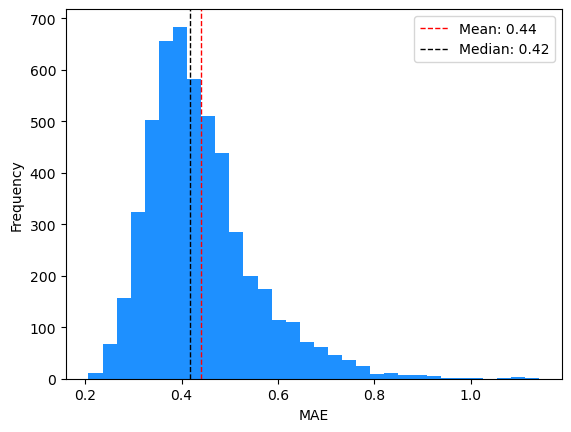

In [11]:
mean_value = maes.mean()[0]
median_value = maes.median()[0]

# Plotting the histogram
plt.hist(maes, bins=32, color='dodgerblue')

# Adding vertical lines for mean and median
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_value:.2f}')
plt.axvline(median_value, color='black', linestyle='dashed', linewidth=1, label=f'Median: {median_value:.2f}')

# Adding titles and labels
plt.xlabel('MAE')
plt.ylabel('Frequency')
plt.legend()

# Display the plot
plt.show()

## MAE vs correlation

In [12]:
correlations = load('data\correlations.joblib')
correlations

<>:1: SyntaxWarning: invalid escape sequence '\c'
<>:1: SyntaxWarning: invalid escape sequence '\c'
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\856928616.py:1: SyntaxWarning: invalid escape sequence '\c'
  correlations = load('data\correlations.joblib')


,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


In [13]:
protein_list = [prot for prot in maes.index if prot in correlations.index]
len(protein_list)

4852

In [14]:
correlations_matched = correlations.reindex(protein_list)
maes_matched = maes.reindex(protein_list)

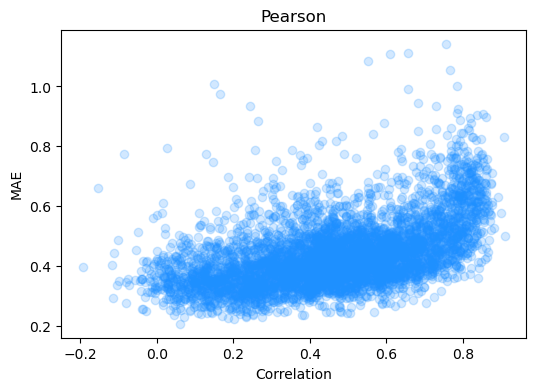

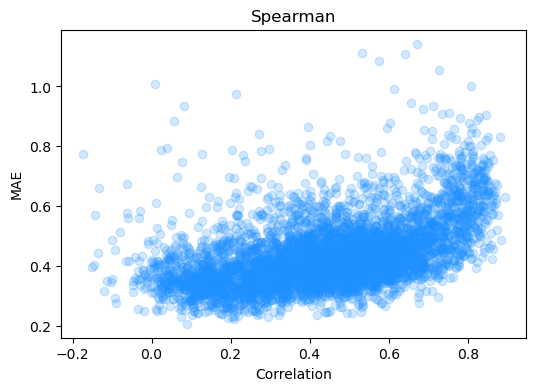

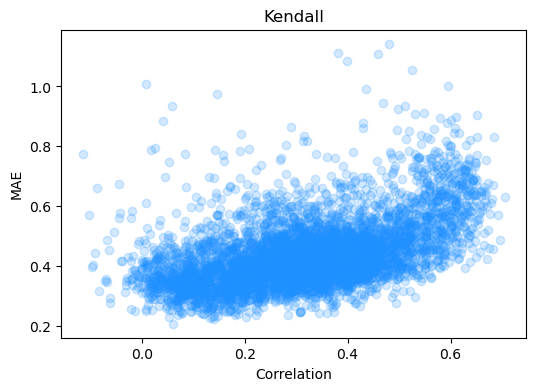

In [15]:
# pearson
plt.figure(figsize=(6, 4))
plt.scatter(correlations_matched['pearson'], maes_matched, alpha=0.2, color='dodgerblue')
plt.title('Pearson')
plt.xlabel('Correlation')
plt.ylabel('MAE')
plt.show()

# Scatter plot: Series 1 vs Series 3
plt.figure(figsize=(6, 4))
plt.scatter(correlations_matched['spearman'], maes_matched, alpha=0.2, color='dodgerblue')
plt.title('Spearman')
plt.xlabel('Correlation')
plt.ylabel('MAE')
plt.show()

# Scatter plot: Series 1 vs Series 4
plt.figure(figsize=(6, 4))
plt.scatter(correlations_matched['kendall'], maes_matched, alpha=0.2, color='dodgerblue')
plt.title('Kendall')
plt.xlabel('Correlation')
plt.ylabel('MAE')
plt.show()

## Best proteins

In [16]:
sorted_proteins = maes['error'].sort_values()
sorted_proteins

protein
PPP1CC      0.206632
PSMC1       0.221194
PTBP1       0.224925
HSPA8       0.227558
EFTUD2      0.229958
              ...   
CDA         1.056300
CDKN2A      1.086523
HLA-B       1.108727
HLA-DRB1    1.111785
ADIRF       1.142821
Name: error, Length: 5113, dtype: float64

In [17]:
sorted_proteins[:100]

protein
PPP1CC    0.206632
PSMC1     0.221194
PTBP1     0.224925
HSPA8     0.227558
EFTUD2    0.229958
            ...   
PPP2CA    0.270527
RBM22     0.270533
PSMA7     0.270554
NUP214    0.271058
NUP85     0.271729
Name: error, Length: 100, dtype: float64

In [18]:
dump(sorted_proteins, 'data\enet\sorted.joblib')
dump(sorted_proteins[:100], 'data\enet\sorted100.joblib')
dump(maes, 'data\enet\maes.joblib')

<>:1: SyntaxWarning: invalid escape sequence '\e'
<>:2: SyntaxWarning: invalid escape sequence '\e'
<>:3: SyntaxWarning: invalid escape sequence '\e'
<>:1: SyntaxWarning: invalid escape sequence '\e'
<>:2: SyntaxWarning: invalid escape sequence '\e'
<>:3: SyntaxWarning: invalid escape sequence '\e'
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\233308060.py:1: SyntaxWarning: invalid escape sequence '\e'
  dump(sorted_proteins, 'data\enet\sorted.joblib')
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\233308060.py:2: SyntaxWarning: invalid escape sequence '\e'
  dump(sorted_proteins[:100], 'data\enet\sorted100.joblib')
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\233308060.py:3: SyntaxWarning: invalid escape sequence '\e'
  dump(maes, 'data\enet\maes.joblib')


['data\\enet\\maes.joblib']

## Sample-wise analysis

In [29]:
loo_maes = enet_results[['LOO sample', 'error']].groupby('LOO sample').mean()

In [20]:
loo_maes

,error
LOO sample,
22RV1_PROSTATE,0.593860
697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.471160
769P_KIDNEY,0.371254
786O_KIDNEY,0.447955
8305C_THYROID,0.531825
...,...
WM1799_SKIN,0.329933
WM2664_SKIN,0.293995
WM793_SKIN,0.452855


C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\2647274679.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  mean_value = loo_maes.mean()[0]
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\2647274679.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  median_value = loo_maes.median()[0]


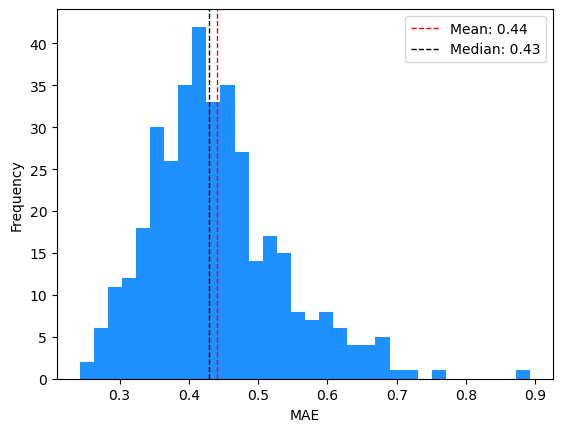

In [21]:
mean_value = loo_maes.mean()[0]
median_value = loo_maes.median()[0]

# Plotting the histogram
plt.hist(loo_maes, bins=32, color='dodgerblue')

# Adding vertical lines for mean and median
plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_value:.2f}')
plt.axvline(median_value, color='black', linestyle='dashed', linewidth=1, label=f'Median: {median_value:.2f}')

# Adding titles and labels
plt.xlabel('MAE')
plt.ylabel('Frequency')
plt.legend()

# Display the plot
plt.show()

In [22]:
sorted_loos = loo_maes['error'].sort_values()
sorted_loos

LOO sample
A2058_SKIN                                   0.242225
SW620_LARGE_INTESTINE                        0.262187
PATU8988T_PANCREAS                           0.264967
COV362_OVARY                                 0.273445
A375_SKIN                                    0.277269
                                               ...   
NCIH1573_LUNG                                0.683143
KNS42_CENTRAL_NERVOUS_SYSTEM                 0.696167
IM95_STOMACH                                 0.714924
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE    0.758347
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE    0.893030
Name: error, Length: 369, dtype: float64

In [23]:
dump(sorted_loos[:100], 'data\enet\loos100.joblib')

<>:1: SyntaxWarning: invalid escape sequence '\e'
<>:1: SyntaxWarning: invalid escape sequence '\e'
C:\Users\ccald\AppData\Local\Temp\ipykernel_2128\1225282038.py:1: SyntaxWarning: invalid escape sequence '\e'
  dump(sorted_loos[:100], 'data\enet\loos100.joblib')


['data\\enet\\loos100.joblib']

## Tissue-specific analysis

In [30]:
loo_maes.head()

,error
LOO sample,
22RV1_PROSTATE,0.593860
697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.471160
769P_KIDNEY,0.371254
786O_KIDNEY,0.447955
8305C_THYROID,0.531825


In [31]:
multi_idx = loo_maes.index.str.split('_', expand=True, n=1)
loo_maes.index = multi_idx
loo_maes.reset_index(inplace=True)
loo_maes.head()

,level_0,level_1,error
0,22RV1,PROSTATE,0.593860
1,697,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.471160
2,769P,KIDNEY,0.371254
3,786O,KIDNEY,0.447955
4,8305C,THYROID,0.531825


In [33]:
tissues = list(set(loo_maes['level_1']))
tissues

['SKIN',
 'CENTRAL_NERVOUS_SYSTEM',
 'SOFT_TISSUE',
 'KIDNEY',
 'BILIARY_TRACT',
 'BREAST',
 'PROSTATE',
 'LIVER',
 'AUTONOMIC_GANGLIA',
 'STOMACH',
 'OVARY',
 'BONE',
 'PLEURA',
 'LUNG',
 'PANCREAS',
 'UPPER_AERODIGESTIVE_TRACT',
 'OESOPHAGUS',
 'URINARY_TRACT',
 'HAEMATOPOIETIC_AND_LYMPHOID_TISSUE',
 'ENDOMETRIUM',
 'LARGE_INTESTINE',
 'THYROID']

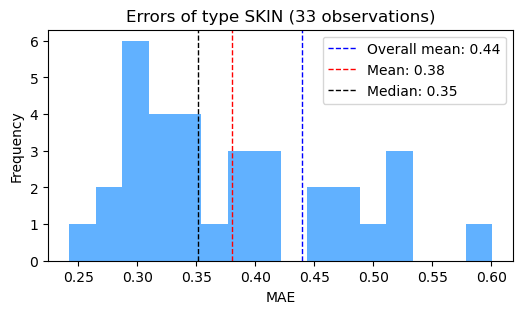

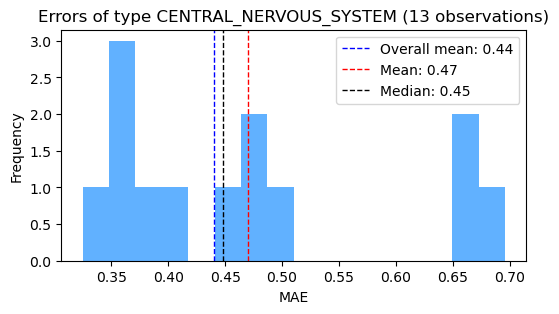

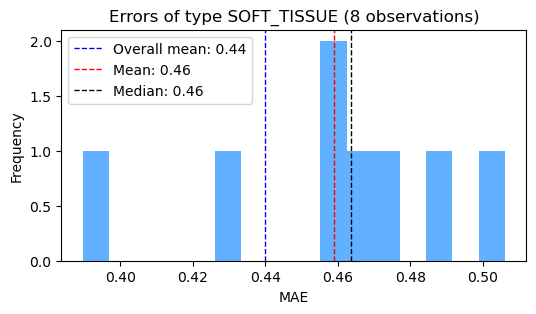

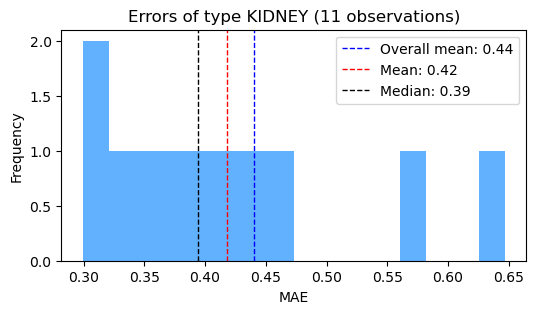

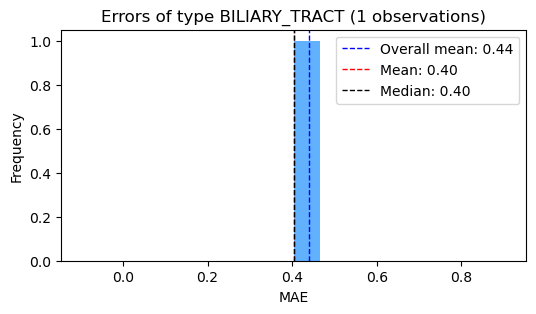

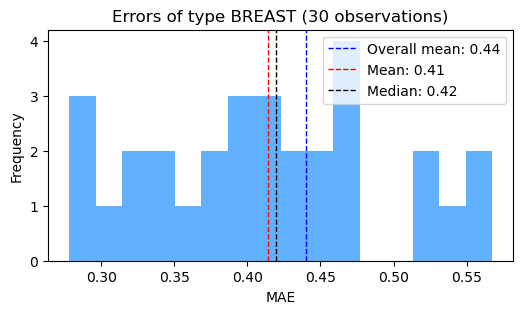

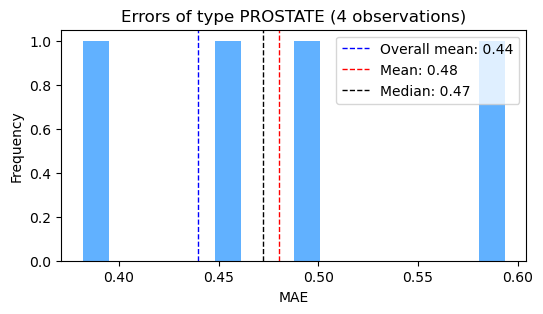

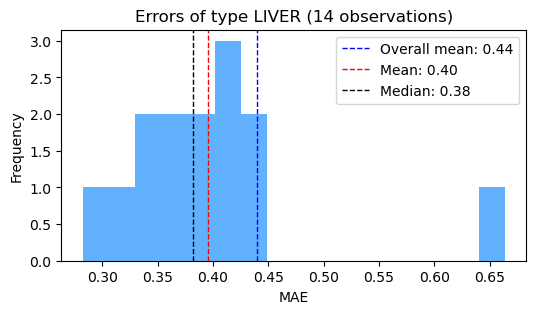

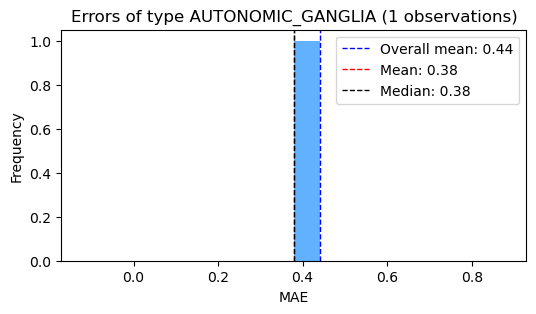

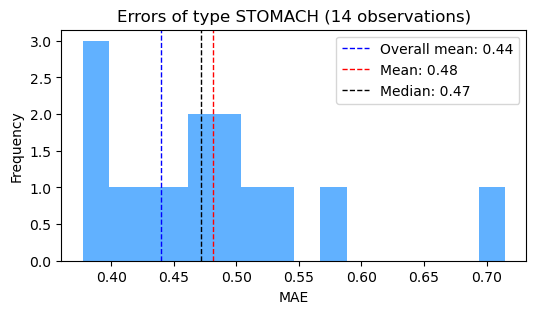

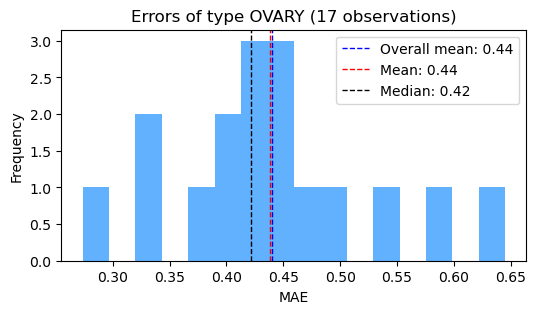

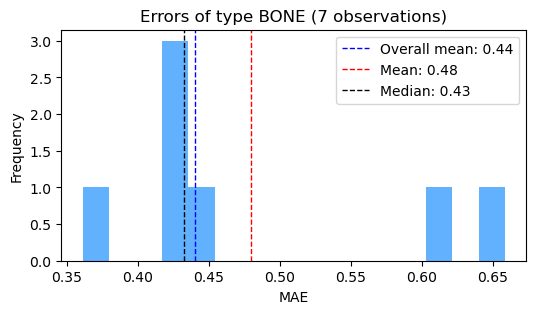

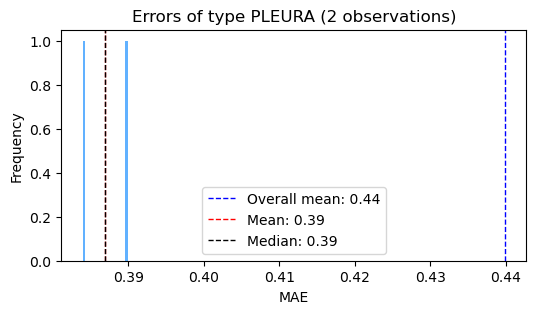

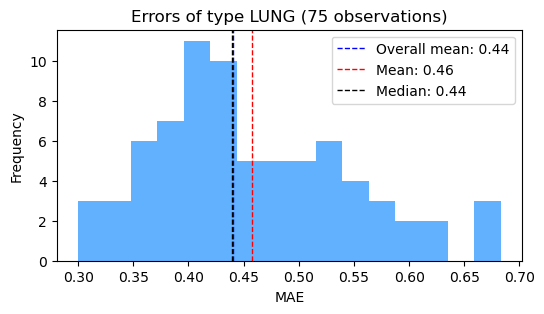

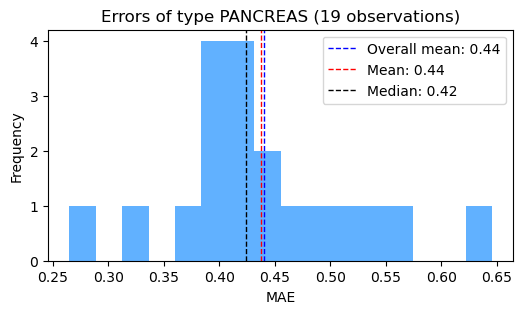

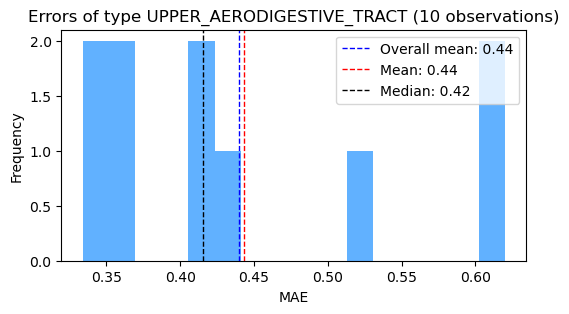

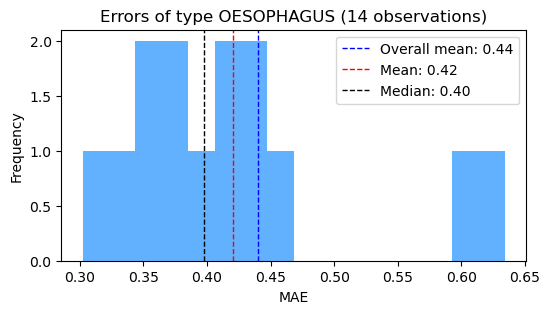

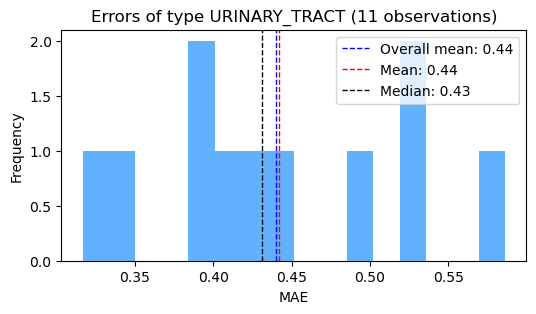

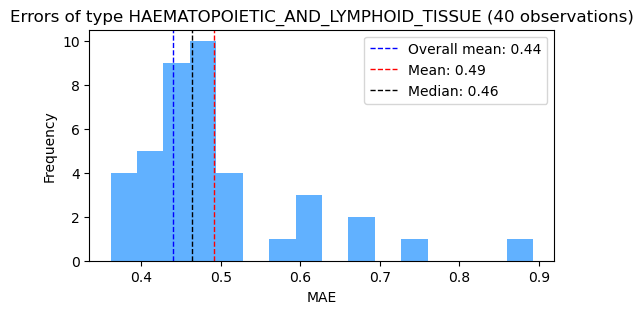

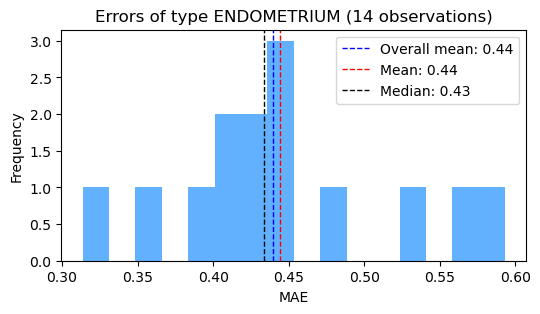

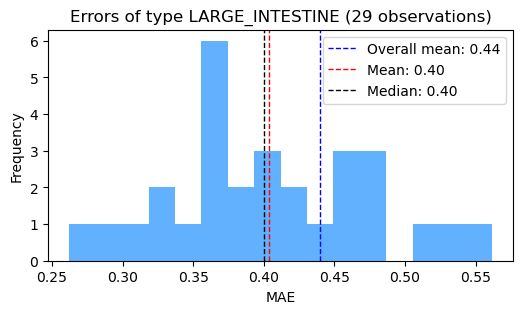

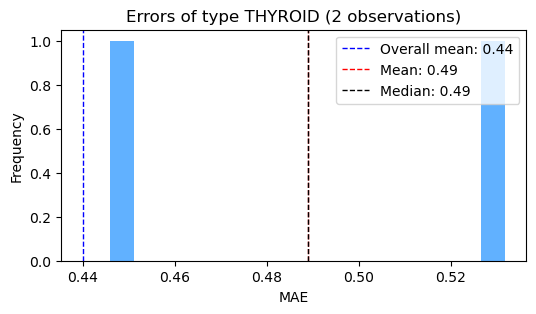

In [38]:
ovr_mean = loo_maes['error'].mean()

for t in tissues:
    subset = loo_maes[loo_maes['level_1'] == t]['error']

    mean_value = subset.mean()
    median_value = subset.median()
        
    plt.figure(figsize=(6, 3))
    plt.hist(subset, bins=16, alpha=0.7, color='dodgerblue')
    plt.axvline(ovr_mean, color='blue', linestyle='dashed', linewidth=1, label=f'Overall mean: {ovr_mean:.2f}')
    plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_value:.2f}')
    plt.axvline(median_value, color='black', linestyle='dashed', linewidth=1, label=f'Median: {median_value:.2f}')
    plt.xlabel('MAE')
    plt.ylabel('Frequency')
    plt.title(f'Errors of type {t} ({len(subset)} observations)')
    plt.legend()
    plt.show()

In [39]:
tissue_errors = [loo_maes[loo_maes['level_1'] == t]['error'].mean() for t in tissues]
tissue_num = [len(loo_maes[loo_maes['level_1'] == t]['error']) for t in tissues]

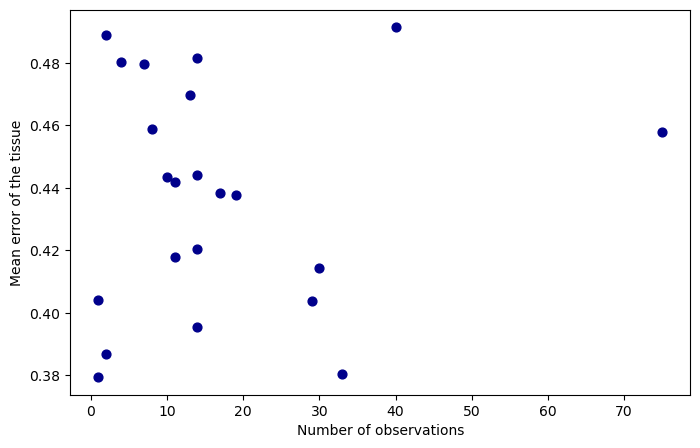

In [40]:
plt.figure(figsize=(8, 5))
plt.scatter(tissue_num, tissue_errors, color='darkblue', marker='o', s=40)

# Adding labels and title
plt.xlabel('Number of observations')
plt.ylabel('Mean error of the tissue')

# Display the plot
plt.show()

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21]),
 [Text(0, 0, 'PROSTATE'),
  Text(1, 0, 'HAEMATOPOIETIC_AND_LYMPHOID_TISSUE'),
  Text(2, 0, 'KIDNEY'),
  Text(3, 0, 'THYROID'),
  Text(4, 0, 'SKIN'),
  Text(5, 0, 'CENTRAL_NERVOUS_SYSTEM'),
  Text(6, 0, 'SOFT_TISSUE'),
  Text(7, 0, 'OVARY'),
  Text(8, 0, 'LUNG'),
  Text(9, 0, 'BONE'),
  Text(10, 0, 'STOMACH'),
  Text(11, 0, 'PANCREAS'),
  Text(12, 0, 'BREAST'),
  Text(13, 0, 'UPPER_AERODIGESTIVE_TRACT'),
  Text(14, 0, 'LARGE_INTESTINE'),
  Text(15, 0, 'ENDOMETRIUM'),
  Text(16, 0, 'LIVER'),
  Text(17, 0, 'URINARY_TRACT'),
  Text(18, 0, 'OESOPHAGUS'),
  Text(19, 0, 'PLEURA'),
  Text(20, 0, 'AUTONOMIC_GANGLIA'),
  Text(21, 0, 'BILIARY_TRACT')])

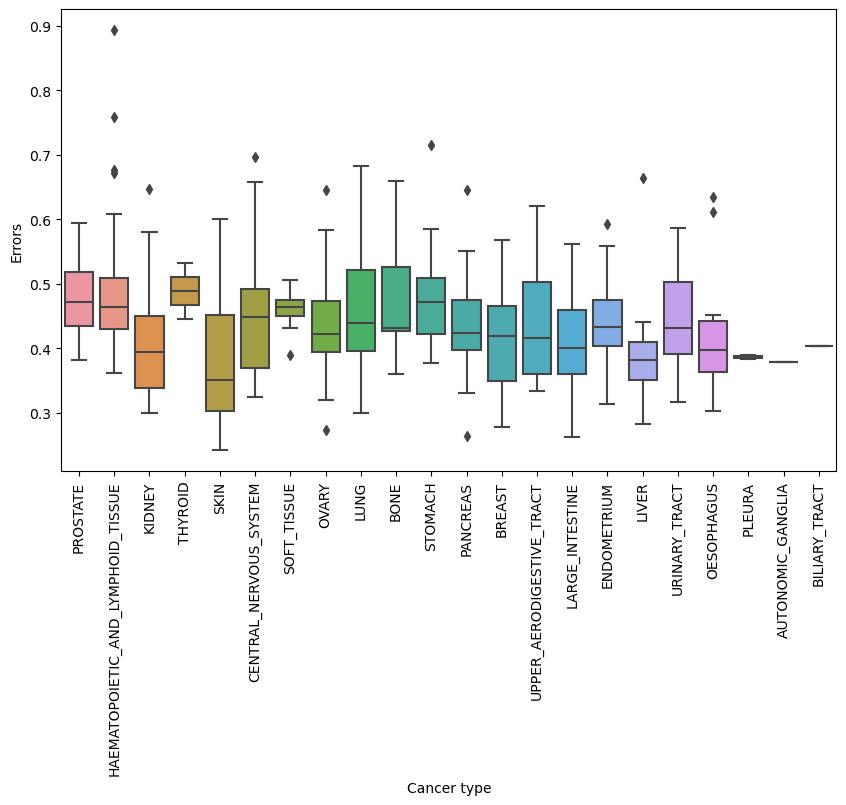

In [41]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='level_1', y='error', data=loo_maes)

plt.xlabel('Cancer type')
plt.ylabel('Errors')
plt.xticks(rotation=90)